# Controlled blurring experiment

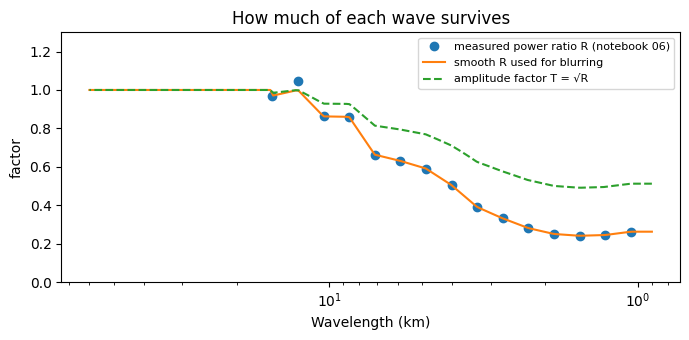

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seafloor as sf

lon, lat, z, ship, dx, dy = sf.load_clean()
DX = float(np.mean(dx))
wl, A, B, _ = sf.block_spectra(z, ship, dx, dy)
R = np.exp(B.mean(0) - A.mean(0))

order = np.argsort(wl); wl_s, R_s = wl[order], np.clip(R[order], 0, 1)
def T_of_wavelength(w_km):
    Rw = np.interp(np.log(w_km), np.log(wl_s), R_s, left=R_s[0], right=1.0)
    Rw = np.where(w_km > wl_s.max(), 1.0, Rw)
    return np.sqrt(Rw)

fig, ax = plt.subplots(figsize=(7, 3.5))
w_plot = np.logspace(np.log10(0.9), np.log10(60), 200)
ax.semilogx(wl, R, "o", label="measured power ratio R (notebook 06)"); ax.semilogx(w_plot, T_of_wavelength(w_plot) ** 2, "-", label="smooth R used for blurring")
ax.semilogx(w_plot, T_of_wavelength(w_plot), "--", label="amplitude factor T = √R")
ax.invert_xaxis(); ax.set(xlabel="Wavelength (km)", ylabel="factor", ylim=(0, 1.3), title="How much of each wave survives"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "11_transfer.png", dpi=200); plt.show()

In [2]:
def degrade(z):
    zf = np.where(np.isnan(z), np.nanmedian(z), z)
    ny, nx = zf.shape
    big = np.pad(zf, ((ny // 4, ny // 4), (nx // 4, nx // 4)), mode="reflect")
    ky = np.fft.fftfreq(big.shape[0], dy); kx = np.fft.fftfreq(big.shape[1], DX)
    K = np.hypot(*np.meshgrid(kx, ky))
    with np.errstate(divide="ignore"):
        W = np.where(K > 0, 1 / K / 1000, 1e9)
    out = np.real(np.fft.ifft2(np.fft.fft2(big) * T_of_wavelength(W)))
    out = out[ny // 4: ny // 4 + ny, nx // 4: nx // 4 + nx]
    out[np.isnan(z)] = np.nan
    return out

z_blur = degrade(z)
print(f"RMS change in depth: {np.sqrt(np.nanmean((z_blur - z) ** 2)):.0f} m")

wl2, A2, _, _ = sf.block_spectra(z_blur, ship, dx, dy)
print(f"Half-power wavelength, blurred ship vs original ship: {sf.half_power_wavelength(wl2, A, A2):.1f} km (should match notebook 06)")

RMS change in depth: 24 m
Half-power wavelength, blurred ship vs original ship: 3.9 km (should match notebook 06)


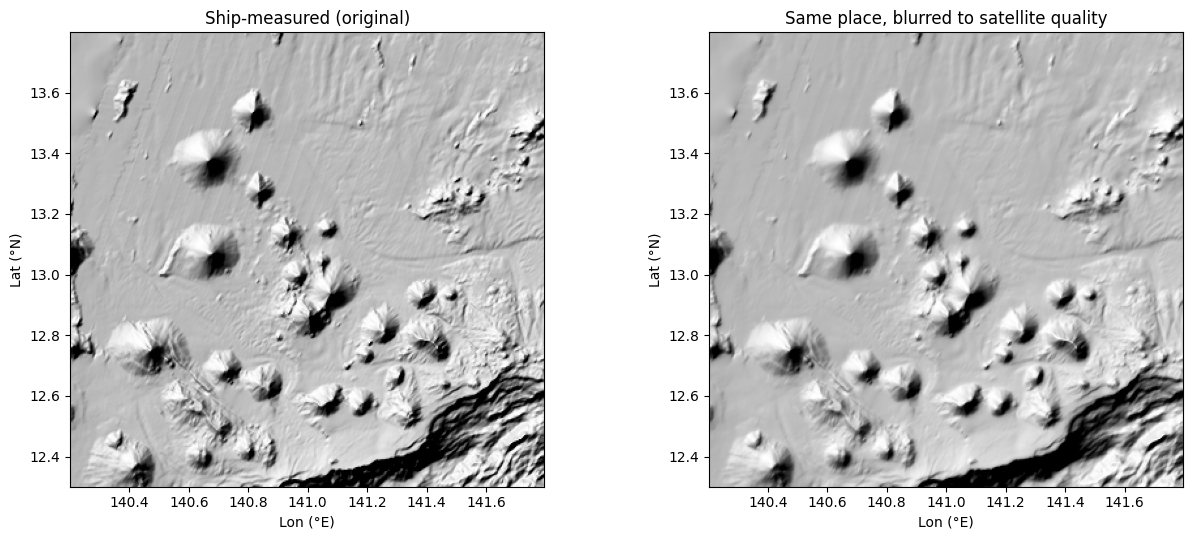

In [3]:
I = (lat >= 12.3) & (lat <= 13.8); J = (lon >= 140.2) & (lon <= 141.8)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, zz, t in zip(axes, [z, z_blur], ["Ship-measured (original)", "Same place, blurred to satellite quality"]):
    sub = zz[np.ix_(I, J)]
    ax.imshow(sf.hillshade(np.where(np.isnan(sub), np.nanmedian(sub), sub), dx[I], dy, exaggeration=4), origin="lower",
              extent=[lon[J][0], lon[J][-1], lat[I][0], lat[I][-1]], cmap="gray", aspect=1.02)
    ax.set(title=t, xlabel="Lon (°E)", ylabel="Lat (°N)")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "11_before_after.png", dpi=200); plt.show()

In [4]:
from scipy.optimize import linear_sum_assignment
SCALES = {"seamount scale (σ 1.5 km)": dict(sigma_m=1500, r_local_m=3000, r_base_m=15000, match_km=3.0, floor=100),
          "fine scale (σ 0.5 km)":      dict(sigma_m=500,  r_local_m=1500, r_base_m=5000,  match_km=1.5, floor=30)}
BINS = [(30, 100), (100, 200), (200, 400), (400, 1000), (1000, 1e9)]
loss_tables = {}
for name, p in SCALES.items():
    kw = dict(sigma_m=p["sigma_m"], r_local_m=p["r_local_m"], r_base_m=p["r_base_m"])
    d0 = sf.detect_peaks(z, dx, dy, lat, lon, h_floor=p["floor"], **kw)
    d1 = sf.detect_peaks(z_blur, dx, dy, lat, lon, h_floor=p["floor"] / 2, **kw)
    a = ship[d0["i"], d0["j"]] & (d0["round"] >= 0.3); b = ship[d1["i"], d1["j"]]
    D = sf.distance_km(d0["lat"][a][:, None], d0["lon"][a][:, None], d1["lat"][b][None], d1["lon"][b][None])
    r, c = linear_sum_assignment(np.where(D <= p["match_km"], D, 1e6)); ok = D[r, c] <= p["match_km"]
    h0 = d0["h"][a]; h_after = np.zeros(len(h0)); h_after[r[ok]] = d1["h"][b][c[ok]]
    lost = h_after < 0.5 * h0
    rows = []
    print(f"\n{name}: {len(h0)} peaks in ship-measured seafloor")
    print(f"{'height (m)':>14s}{'n':>6s}{'lost':>7s}{'height kept (median)':>24s}")
    for lo_, hi_ in BINS:
        m = (h0 >= lo_) & (h0 < hi_)
        if m.sum() < 5: continue
        rows.append((lo_, hi_, m.sum(), lost[m].mean(), np.median(h_after[m] / h0[m])))
        print(f"{lo_:>7.0f}–{hi_ if hi_ < 1e8 else '+':<6}{m.sum():6d}{lost[m].mean():7.0%}{rows[-1][4]:24.2f}")
    loss_tables[name] = np.array(rows)


seamount scale (σ 1.5 km): 278 peaks in ship-measured seafloor
    height (m)     n   lost    height kept (median)
    100–200       13     8%                    0.99
    200–400       25     0%                    0.97
    400–1000      96     1%                    0.99
   1000–+        144     3%                    0.99



fine scale (σ 0.5 km): 1443 peaks in ship-measured seafloor
    height (m)     n   lost    height kept (median)
     30–100      211    29%                    0.83
    100–200      224    33%                    0.80
    200–400      331    24%                    0.85
    400–1000     500    22%                    0.89
   1000–+        177    12%                    0.93


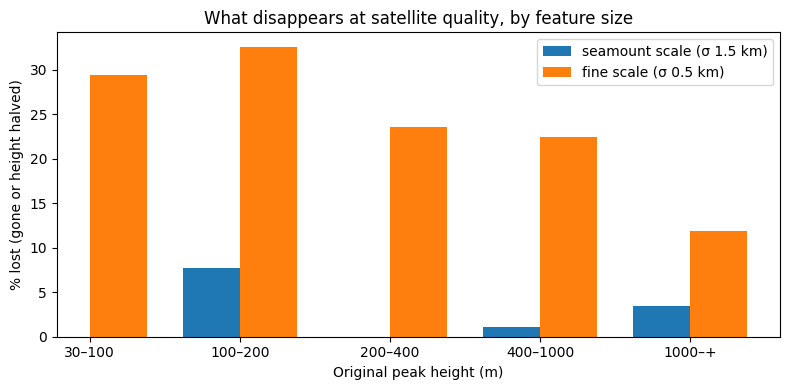

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
all_bins = sorted({(a, b) for t in loss_tables.values() for a, b in t[:, :2]})
width = 0.38
for k, (name, t) in enumerate(loss_tables.items()):
    idx = [all_bins.index((a, b)) for a, b in t[:, :2]]
    ax.bar(np.array(idx) + (k - 0.5) * width, t[:, 3] * 100, width, label=name)
ax.set_xticks(range(len(all_bins)), [f"{int(a)}–{int(b) if b < 1e8 else '+'}" for a, b in all_bins])
ax.set(xlabel="Original peak height (m)", ylabel="% lost (gone or height halved)", title="What disappears at satellite quality, by feature size")
ax.legend(); fig.tight_layout(); fig.savefig(sf.FIG_DIR / "11_loss.png", dpi=200); plt.show()

In [6]:
import json
json.dump({k: v.tolist() for k, v in loss_tables.items()}, open(sf.DATA_DIR / "11_loss.json", "w"))
print("KEY NUMBERS")
print(f"  Blurred-ship half-power check: {sf.half_power_wavelength(wl2, A, A2):.1f} km (target ≈ notebook 06 value)")
for name, t in loss_tables.items():
    for lo_, hi_, n, lost, kept in t:
        print(f"  {name:26s} {int(lo_)}–{int(hi_) if hi_ < 1e8 else '+'} m: n={int(n)}, lost {lost:.0%}, height kept ×{kept:.2f}")

KEY NUMBERS
  Blurred-ship half-power check: 3.9 km (target ≈ notebook 06 value)
  seamount scale (σ 1.5 km)  100–200 m: n=13, lost 8%, height kept ×0.99
  seamount scale (σ 1.5 km)  200–400 m: n=25, lost 0%, height kept ×0.97
  seamount scale (σ 1.5 km)  400–1000 m: n=96, lost 1%, height kept ×0.99
  seamount scale (σ 1.5 km)  1000–+ m: n=144, lost 3%, height kept ×0.99
  fine scale (σ 0.5 km)      30–100 m: n=211, lost 29%, height kept ×0.83
  fine scale (σ 0.5 km)      100–200 m: n=224, lost 33%, height kept ×0.80
  fine scale (σ 0.5 km)      200–400 m: n=331, lost 24%, height kept ×0.85
  fine scale (σ 0.5 km)      400–1000 m: n=500, lost 22%, height kept ×0.89
  fine scale (σ 0.5 km)      1000–+ m: n=177, lost 12%, height kept ×0.93
